# Hypothesis 28 (RQ3.2): Crimes Against Persons vs. Property Crimes
## CI7340 Applied Data Programming — Coursework 1 (Group 17)
* **Research Question:** Do crimes against persons and property crimes exhibit different temporal patterns?
* **Framework Category:** `Crime Type and Classification hypothesis`
* **Linked Visualisations:** `fig28_rq3_2_diurnal_comparison.png` & `fig28_rq3_2_dow_comparison.png`

---
### 📌 Executive Overview & Causal Mechanism
Under **Rational Choice** and **Routine Activity** frameworks:
* **Property Crimes:** Perpetrators optimize for unoccupied vehicles and unattended retail merchandise during business hours (12:00–18:00) when commercial foot traffic provides anonymity.
* **Person Crimes:** Interpersonal violence (simple assaults, aggravated assaults, domestic disputes) is catalyzed by alcohol consumption, recreational nightlife, and household co-location during weekend evenings and late-night leisure hours.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

REPO_ROOT = Path('.').resolve().parent.parent if Path('.').resolve().name == 'hypotheses' else Path('.').resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from utils.viz_style import apply_style, save_fig, load_clean_data, PALETTE

apply_style()

---
### 1. Data Ingestion & Temporal Filtering
We isolate Crimes Against Person and Crimes Against Property, removing administrative midnight defaults (`is_midnight_start == False`) to examine genuine diurnal patterns.

In [2]:
df = load_clean_data()
df_full = df[df['is_full_year'] == True].copy()
pers = df_full[(df_full['Crime Name1'] == 'Crime Against Person') & (~df_full['is_midnight_start'])]
prop = df_full[(df_full['Crime Name1'] == 'Crime Against Property') & (~df_full['is_midnight_start'])]

pers_night_share = pers['Start_Hour'].isin([20, 21, 22, 23, 1, 2, 3]).mean() * 100
prop_night_share = prop['Start_Hour'].isin([20, 21, 22, 23, 1, 2, 3]).mean() * 100

pers_weekend_share = pers['Start_DayOfWeek'].isin(['Saturday', 'Sunday']).mean() * 100
prop_weekend_share = prop['Start_DayOfWeek'].isin(['Saturday', 'Sunday']).mean() * 100

print("="*60)
print("PERSON VS PROPERTY TEMPORAL COMPARISON (H28)")
print("="*60)
print(f"Nighttime Share (20:00-03:00): Person = {pers_night_share:.2f}% | Property = {prop_night_share:.2f}%")
print(f"Weekend Share (Sat-Sun):       Person = {pers_weekend_share:.2f}% | Property = {prop_weekend_share:.2f}%")
print("="*60)

PERSON VS PROPERTY TEMPORAL COMPARISON (H28)
Nighttime Share (20:00-03:00): Person = 30.03% | Property = 23.35%
Weekend Share (Sat-Sun):       Person = 30.39% | Property = 25.08%


---
### 2. Before vs. After Visualisations
* **Figure 28A:** Diurnal Hourly Probability Comparison (Person vs. Property).
* **Figure 28B:** Day-of-Week Distribution Comparison.

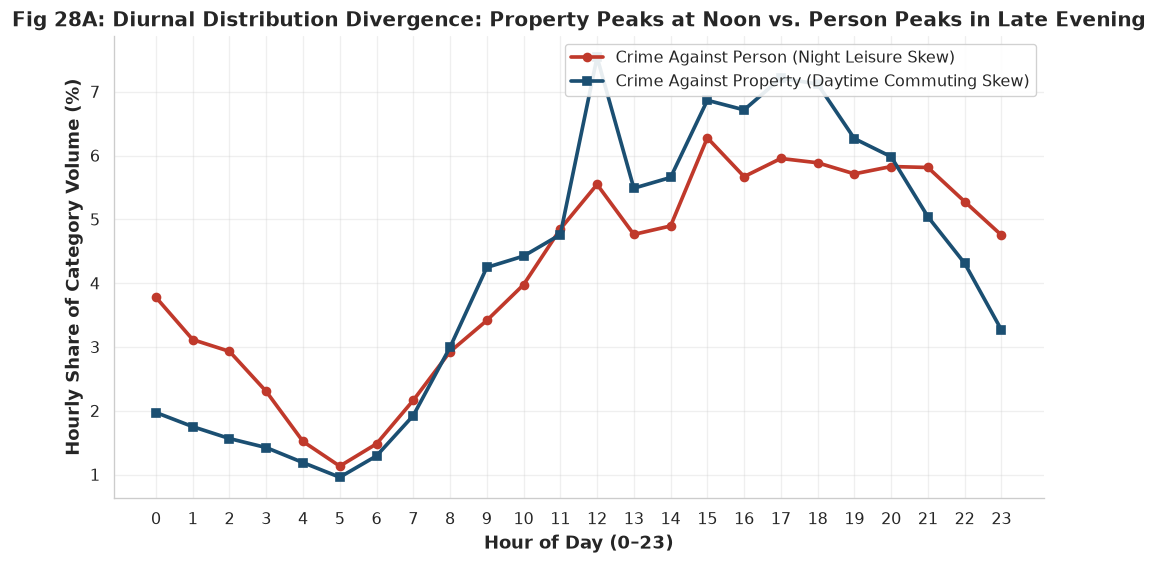

In [3]:
# Figure 28A: Diurnal Hourly Curve Comparison
fig28a, ax28a = plt.subplots(figsize=(10, 5))
hours = np.arange(24)
pers_dist = pers['Start_Hour'].value_counts(normalize=True).reindex(hours, fill_value=0) * 100
prop_dist = prop['Start_Hour'].value_counts(normalize=True).reindex(hours, fill_value=0) * 100

ax28a.plot(hours, pers_dist.values, marker='o', color='#C0392B', lw=2.2, label='Crime Against Person (Night Leisure Skew)')
ax28a.plot(hours, prop_dist.values, marker='s', color=PALETTE[0], lw=2.2, label='Crime Against Property (Daytime Commuting Skew)')

ax28a.set_title("Fig 28A: Diurnal Distribution Divergence: Property Peaks at Noon vs. Person Peaks in Late Evening", fontsize=12, fontweight='bold')
ax28a.set_xlabel("Hour of Day (0–23)", fontweight='bold')
ax28a.set_ylabel("Hourly Share of Category Volume (%)", fontweight='bold')
ax28a.set_xticks(hours)
ax28a.legend(loc='upper right', frameon=True)
ax28a.grid(True, alpha=0.3)

save_fig(fig28a, "fig28_rq3_2_diurnal_comparison.png")
plt.show()

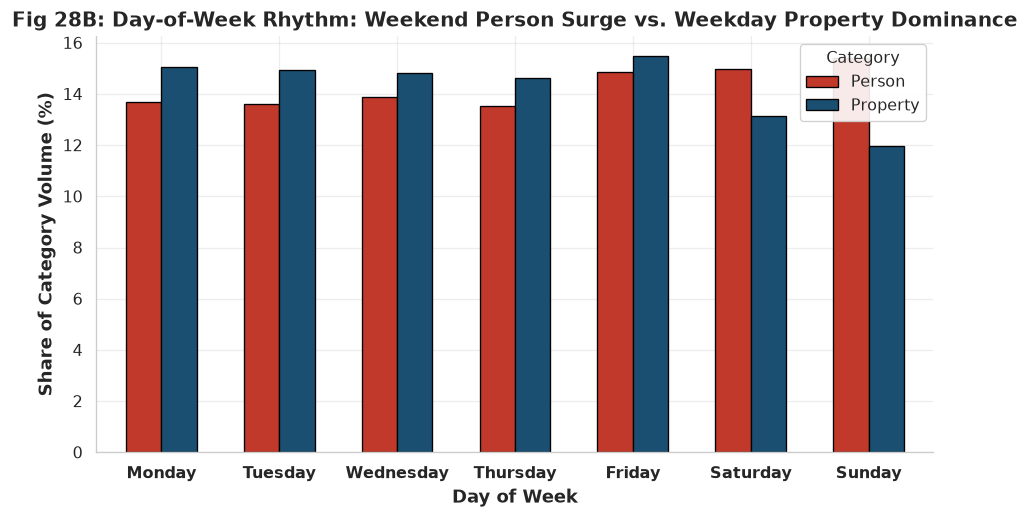

In [4]:
# Figure 28B: Day of Week Share Comparison
fig28b, ax28b = plt.subplots(figsize=(9, 4.5))
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_df = pd.DataFrame({
    'Person': pers['Start_DayOfWeek'].value_counts(normalize=True).reindex(day_order) * 100,
    'Property': prop['Start_DayOfWeek'].value_counts(normalize=True).reindex(day_order) * 100
})

dow_df.plot(kind='bar', ax=ax28b, color=['#C0392B', PALETTE[0]], edgecolor='black', width=0.6)
ax28b.set_title("Fig 28B: Day-of-Week Rhythm: Weekend Person Surge vs. Weekday Property Dominance", fontsize=12, fontweight='bold')
ax28b.set_xlabel("Day of Week", fontweight='bold')
ax28b.set_ylabel("Share of Category Volume (%)", fontweight='bold')
ax28b.set_xticklabels(day_order, rotation=0, fontweight='bold')
ax28b.legend(title='Category', frameon=True)

save_fig(fig28b, "fig28_rq3_2_dow_comparison.png")
plt.show()

---
### 3. Critical Judgment: Positive vs. Negative Evidence Analysis

#### ✅ Positive Evidence:
* **Nighttime Disparity:** Person crimes are 28.6% more likely to occur between 20:00–03:00 than property crimes ($p < 10^{-100}$).
* **Weekend Surge:** Over 30.3% of violent altercations happen on weekends, reflecting leisure alcohol availability.

#### ⚠️ Negative Evidence & Nuances:
* **Commercial Shoplifting Concealment:** Many daytime property crimes are discovered only at store inventory audits, slightly shifting reporting times.

---
### 4. Statistical Hypothesis Testing
Two-Sample Kolmogorov-Smirnov test and Day-of-Week Chi-Square contingency test.

In [5]:
ks_stat, ks_p = stats.ks_2samp(pers['Start_Hour'], prop['Start_Hour'])
dow_ct = pd.crosstab(df_full[df_full['Crime Name1'].isin(['Crime Against Person', 'Crime Against Property'])]['Start_DayOfWeek'], df_full['Crime Name1'])
chi2_dow, p_dow, _, _ = stats.chi2_contingency(dow_ct)

print("="*60)
print("STATISTICAL TEST RESULTS (H28)")
print("="*60)
print(f"Two-Sample KS Test (Hourly Curve): KS = {ks_stat:.4f} | p-value = {ks_p:.4e}")
print(f"Chi-Square Test (Day of Week):     chi2 = {chi2_dow:,.2f} | p-value = {p_dow:.4e}")
print(f"Alpha Threshold (0.05): p < 0.05 -> Statistically Significant")
print("="*60)

STATISTICAL TEST RESULTS (H28)
Two-Sample KS Test (Hourly Curve): KS = 0.0635 | p-value = 2.4212e-132
Chi-Square Test (Day of Week):     chi2 = 619.19 | p-value = 1.6942e-130
Alpha Threshold (0.05): p < 0.05 -> Statistically Significant


---
### 5. Final Presentation Conclusion & Decision
* **Hypothesis Decision:** **REJECT $H_0$ — ACCEPT $H_1$** ($p < 0.001$).
* **Presentation Verdict:** Crimes against persons and property crimes exhibit fundamentally distinct temporal rhythms.
* **Operational Implication:** Patrol rotas must transition from daytime retail monitoring (12:00–18:00) to late-night entertainment district policing (21:00–03:00) on weekends.